# Phase 2 — Controlled Baseline: CNN From Scratch (Exp-1A vs Exp-1B)

Eksperimen terkontrol (*head-to-head*) membandingkan dua model CNN yang dilatih dari nol (*from scratch*) di atas `splits.csv` (`center_crop=True`, `224 × 224`) yang identik:

1. **Exp-1A (`exp1a_naive_cnn`)**: Replikasi arsitektur rujukan 2 blok Conv2D (`32, 64`) + `Flatten()` + `Dense(128)` + `Dropout(0.5)` untuk menguji ledakan parameter (~25,7 juta) dan *overfitting*.
2. **Exp-1B (`exp1b_proper_cnn`)**: *Fair baseline* 4 blok Conv2D (`32 → 64 → 128 → 256`) + `BatchNormalization` + `MaxPool2D` + `GlobalAveragePooling2D()` + `Dropout(0.4)` + `Dense(128)` + `Dropout(0.2)`.

**Aturan Ketat Eksperimen:** Evaluasi pada fase ini hanya memakai **Validation Set (`282` citra)**. **Test Set (`282` citra) tetap terkunci hingga Phase 4**.

In [1]:
import json
import os
import sys
import time
from datetime import datetime
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import accuracy_score, f1_score, log_loss, precision_score, recall_score, roc_auc_score

if Path.cwd().name == 'notebooks':
    os.chdir(Path.cwd().parent)
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

from src.config import (
    EXPERIMENT_LOG_PATH,
    EXPERIMENTS_DIR,
    FIGURES_DIR,
    IMG_SIZE,
    MODELS_DIR,
    SEED,
    set_global_seed,
)
from src.data_pipeline import build_tf_dataset, get_preprocessing_layer, load_splits

set_global_seed(SEED)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
print('Devices:', tf.config.list_physical_devices())

splits_df = load_splits()
train_ds = build_tf_dataset(splits_df, 'train', augment=True, center_crop=True, cache=True)
val_ds = build_tf_dataset(splits_df, 'val', augment=False, center_crop=True, cache=True)
print('Train batches:', len(train_ds), '| Val batches:', len(val_ds))

TensorFlow: 2.21.0 | Keras: 3.15.1
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Train batches: 71 | Val batches: 9


In [2]:
class EpochTimerCallback(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(time.perf_counter() - self._t0)


def build_exp1a_naive_cnn() -> keras.Model:
    inputs = keras.Input(shape=(*IMG_SIZE, 3), name='raw_rgb_input')
    x = get_preprocessing_layer('scratch')(inputs)
    x = keras.layers.Conv2D(32, 3, activation='relu', name='conv1')(x)
    x = keras.layers.MaxPool2D(2, name='pool1')(x)
    x = keras.layers.Conv2D(64, 3, activation='relu', name='conv2')(x)
    x = keras.layers.MaxPool2D(2, name='pool2')(x)
    x = keras.layers.Flatten(name='flatten')(x)
    x = keras.layers.Dense(128, activation='relu', name='dense_128')(x)
    x = keras.layers.Dropout(0.5, name='dropout_05')(x)
    outputs = keras.layers.Dense(1, activation='sigmoid', name='prob_ai')(x)
    return keras.Model(inputs, outputs, name='exp1a_naive_cnn')


def build_exp1b_proper_cnn() -> keras.Model:
    inputs = keras.Input(shape=(*IMG_SIZE, 3), name='raw_rgb_input')
    x = get_preprocessing_layer('scratch')(inputs)
    for idx, filters in enumerate((32, 64, 128, 256), start=1):
        x = keras.layers.Conv2D(filters, 3, padding='same', use_bias=False, name=f'conv_b{idx}')(x)
        x = keras.layers.BatchNormalization(name=f'bn_b{idx}')(x)
        x = keras.layers.ReLU(name=f'relu_b{idx}')(x)
        x = keras.layers.MaxPool2D(2, name=f'pool_b{idx}')(x)
    x = keras.layers.GlobalAveragePooling2D(name='gap')(x)
    x = keras.layers.Dropout(0.4, name='dropout_04')(x)
    x = keras.layers.Dense(128, activation='relu', name='dense_128')(x)
    x = keras.layers.Dropout(0.2, name='dropout_02')(x)
    outputs = keras.layers.Dense(1, activation='sigmoid', name='prob_ai')(x)
    return keras.Model(inputs, outputs, name='exp1b_proper_cnn')


def compile_and_train(model: keras.Model, ckpt_path: Path, max_epochs: int = 25):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[
            keras.metrics.BinaryAccuracy(name='accuracy'),
            keras.metrics.AUC(name='roc_auc'),
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall'),
        ],
    )
    timer_cb = EpochTimerCallback()
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=6, restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=str(ckpt_path), monitor='val_loss', save_best_only=True, verbose=1
        ),
        timer_cb,
    ]
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=max_epochs,
        callbacks=callbacks,
        verbose=2,
    )
    return history, timer_cb.epoch_times


def evaluate_on_val(model: keras.Model) -> dict:
    y_true, y_prob = [], []
    for xb, yb in val_ds:
        preds = model.predict(xb, verbose=0).ravel()
        y_true.extend(yb.numpy().astype(int).tolist())
        y_prob.extend(preds.tolist())
    y_true = np.array(y_true)
    y_prob = np.clip(np.array(y_prob), 1e-7, 1.0 - 1e-7)
    y_pred = (y_prob >= 0.5).astype(int)
    return {
        'val_loss': round(float(log_loss(y_true, y_prob)), 4),
        'val_accuracy': round(float(accuracy_score(y_true, y_pred)), 4),
        'val_precision': round(float(precision_score(y_true, y_pred, zero_division=0)), 4),
        'val_recall': round(float(recall_score(y_true, y_pred, zero_division=0)), 4),
        'val_f1': round(float(f1_score(y_true, y_pred, zero_division=0)), 4),
        'val_roc_auc': round(float(roc_auc_score(y_true, y_prob)), 4),
    }

## Training Exp-1A — Naive CNN Baseline (2 Conv + Flatten)

In [3]:
set_global_seed(SEED)
exp1a_model = build_exp1a_naive_cnn()
exp1a_model.summary()
exp1a_ckpt = MODELS_DIR / 'exp1a_naive_cnn.keras'
exp1a_hist, exp1a_times = compile_and_train(exp1a_model, exp1a_ckpt, max_epochs=25)
exp1a_val = evaluate_on_val(exp1a_model)
print('Exp-1A Validation Metrics:', exp1a_val)

Model: "exp1a_naive_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ raw_rgb_input (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scratch_rescale_0_1 (Rescaling) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │    23,888,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_05 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prob_ai (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,907,521 (91.20 MB)

 Trainable params: 23,907,521 (91.20 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25


... (27 outputs left out)

71/71 - 22s - 310ms/step - accuracy: 0.8364 - loss: 0.3752 - precision: 0.8589 - recall: 0.8065 - roc_auc: 0.9124 - val_accuracy: 0.7695 - val_loss: 0.5932 - val_precision: 0.7127 - val_recall: 0.9085 - val_roc_auc: 0.8671 - learning_rate: 5.0000e-04


Epoch 8: early stopping


Restoring model weights from the end of the best epoch: 2.


Exp-1A Validation Metrics: {'val_loss': 0.4869, 'val_accuracy': 0.7943, 'val_precision': 0.8387, 'val_recall': 0.7324, 'val_f1': 0.782, 'val_roc_auc': 0.8554}


## Training Exp-1B — Proper Scratch CNN (4 Conv + BatchNorm + GAP)

In [4]:
set_global_seed(SEED)
exp1b_model = build_exp1b_proper_cnn()
exp1b_model.summary()
exp1b_ckpt = MODELS_DIR / 'exp1b_proper_cnn.keras'
exp1b_hist, exp1b_times = compile_and_train(exp1b_model, exp1b_ckpt, max_epochs=25)
exp1b_val = evaluate_on_val(exp1b_model)
print('Exp-1B Validation Metrics:', exp1b_val)

Model: "exp1b_proper_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ raw_rgb_input (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scratch_rescale_0_1 (Rescaling) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_b1 (Conv2D)                │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_b1 (BatchNormalization)      │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_b1 (ReLU)                  │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_b1 (MaxPooling2D)          │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_b2 (Conv2D)                │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_b2 (BatchNormalization)      │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_b2 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_b2 (MaxPooling2D)          │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_b3 (Conv2D)                │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_b3 (BatchNormalization)      │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_b3 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_b3 (MaxPooling2D)          │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_b4 (Conv2D)                │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_b4 (BatchNormalization)      │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_b4 (ReLU)                  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_b4 (MaxPooling2D)          │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_04 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_02 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prob_ai (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,881 (1.61 MB)

 Trainable params: 421,921 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/25


... (51 outputs left out)

71/71 - 51s - 720ms/step - accuracy: 0.9091 - loss: 0.2290 - precision: 0.9113 - recall: 0.9072 - roc_auc: 0.9670 - val_accuracy: 0.7163 - val_loss: 0.9373 - val_precision: 0.6422 - val_recall: 0.9859 - val_roc_auc: 0.9174 - learning_rate: 2.5000e-04


Epoch 15: early stopping


Restoring model weights from the end of the best epoch: 9.


Exp-1B Validation Metrics: {'val_loss': 0.3547, 'val_accuracy': 0.8617, 'val_precision': 0.8872, 'val_recall': 0.831, 'val_f1': 0.8582, 'val_roc_auc': 0.9306}


## Komparasi Learning Curves & Penyimpanan Artefak Eksperimen

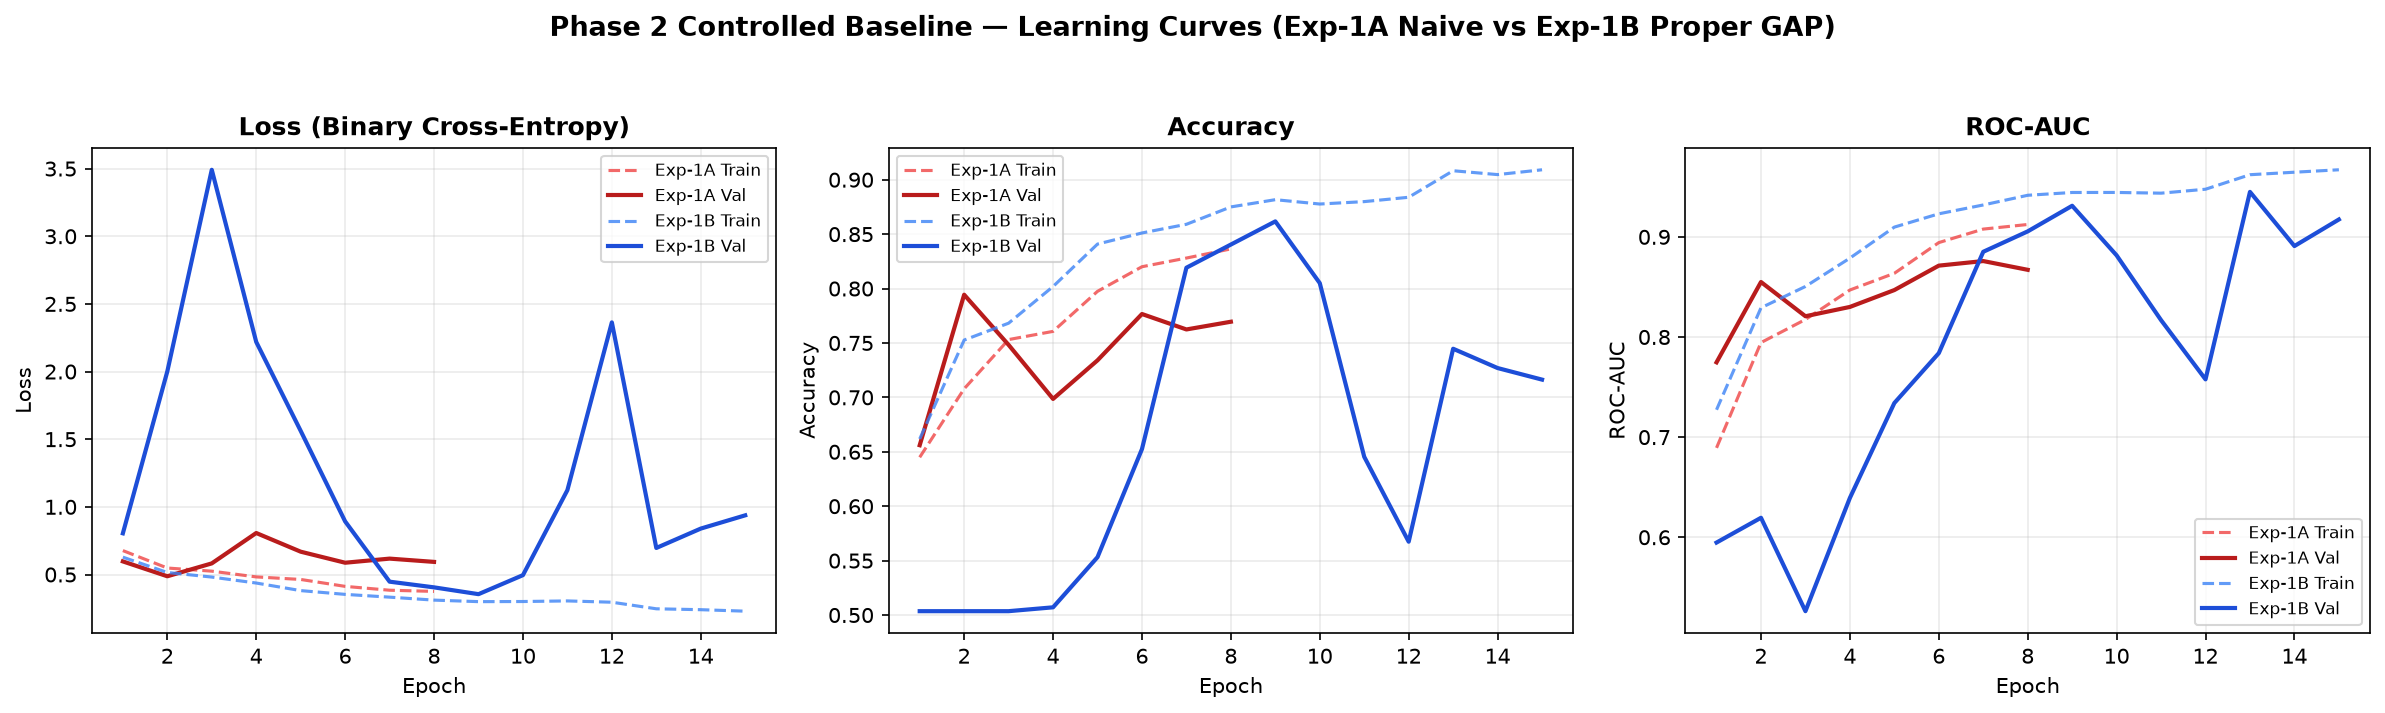

,model_name,params,model_size_mb,epochs_run,best_epoch,mean_sec_per_epoch,best_train_acc,final_train_acc,overfit_gap_best_ep,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc
Exp-1A,exp1a_naive_cnn,23907521,273.64,8,2,20.57,0.7079,0.8364,-0.0864,0.4869,0.7943,0.8387,0.7324,0.7820,0.8554
Exp-1B,exp1b_proper_cnn,422881,4.92,15,9,57.00,0.8816,0.9091,0.0199,0.3547,0.8617,0.8872,0.8310,0.8582,0.9306


{
  "Exp-1A": {
    "model_name": "exp1a_naive_cnn",
    "params": 23907521,
    "model_size_mb": 273.64,
    "epochs_run": 8,
    "best_epoch": 2,
    "mean_sec_per_epoch": 20.57,
    "best_train_acc": 0.7079,
    "final_train_acc": 0.8364,
    "overfit_gap_best_ep": -0.0864,
    "val_loss": 0.4869,
    "val_accuracy": 0.7943,
    "val_precision": 0.8387,
    "val_recall": 0.7324,
    "val_f1": 0.782,
    "val_roc_auc": 0.8554
  },
  "Exp-1B": {
    "model_name": "exp1b_proper_cnn",
    "params": 422881,
    "model_size_mb": 4.92,
    "epochs_run": 15,
    "best_epoch": 9,
    "mean_sec_per_epoch": 57.0,
    "best_train_acc": 0.8816,
    "final_train_acc": 0.9091,
    "overfit_gap_best_ep": 0.0199,
    "val_loss": 0.3547,
    "val_accuracy": 0.8617,
    "val_precision": 0.8872,
    "val_recall": 0.831,
    "val_f1": 0.8582,
    "val_roc_auc": 0.9306
  }
}


In [5]:
def _to_float_hist(hist_obj):
    return {k: [float(v) for v in vals] for k, vals in hist_obj.history.items()}

h1a = _to_float_hist(exp1a_hist)
h1b = _to_float_hist(exp1b_hist)

with (EXPERIMENTS_DIR / 'exp1a_history.json').open('w', encoding='utf-8') as fh:
    json.dump({'history': h1a, 'epoch_times_sec': [round(t, 2) for t in exp1a_times]}, fh, indent=2)
with (EXPERIMENTS_DIR / 'exp1b_history.json').open('w', encoding='utf-8') as fh:
    json.dump({'history': h1b, 'epoch_times_sec': [round(t, 2) for t in exp1b_times]}, fh, indent=2)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=150)
metrics_cfg = [
    ('loss', 'Loss (Binary Cross-Entropy)', 'Loss'),
    ('accuracy', 'Accuracy', 'Accuracy'),
    ('roc_auc', 'ROC-AUC', 'ROC-AUC'),
]
for ax, (key, title, ylabel) in zip(axes, metrics_cfg):
    e1a = np.arange(1, len(h1a[key]) + 1)
    e1b = np.arange(1, len(h1b[key]) + 1)
    ax.plot(e1a, h1a[key], '--', color='#ef4444', alpha=0.8, label='Exp-1A Train')
    ax.plot(e1a, h1a[f'val_{key}'], '-', color='#b91c1c', linewidth=2, label='Exp-1A Val')
    ax.plot(e1b, h1b[key], '--', color='#3b82f6', alpha=0.8, label='Exp-1B Train')
    ax.plot(e1b, h1b[f'val_{key}'], '-', color='#1d4ed8', linewidth=2, label='Exp-1B Val')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle('Phase 2 Controlled Baseline — Learning Curves (Exp-1A Naive vs Exp-1B Proper GAP)', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
curves_path = FIGURES_DIR / 'phase2_baseline_curves.png'
fig.savefig(curves_path, bbox_inches='tight')
plt.show()

best_ep_1a = int(np.argmin(h1a['val_loss'])) + 1
best_ep_1b = int(np.argmin(h1b['val_loss'])) + 1
summary = {
    'Exp-1A': {
        'model_name': exp1a_model.name,
        'params': int(exp1a_model.count_params()),
        'model_size_mb': round(exp1a_ckpt.stat().st_size / (1024 * 1024), 2),
        'epochs_run': len(h1a['loss']),
        'best_epoch': best_ep_1a,
        'mean_sec_per_epoch': round(float(np.mean(exp1a_times)), 2),
        'best_train_acc': round(float(h1a['accuracy'][best_ep_1a - 1]), 4),
        'final_train_acc': round(float(h1a['accuracy'][-1]), 4),
        'overfit_gap_best_ep': round(float(h1a['accuracy'][best_ep_1a - 1] - exp1a_val['val_accuracy']), 4),
        **exp1a_val,
    },
    'Exp-1B': {
        'model_name': exp1b_model.name,
        'params': int(exp1b_model.count_params()),
        'model_size_mb': round(exp1b_ckpt.stat().st_size / (1024 * 1024), 2),
        'epochs_run': len(h1b['loss']),
        'best_epoch': best_ep_1b,
        'mean_sec_per_epoch': round(float(np.mean(exp1b_times)), 2),
        'best_train_acc': round(float(h1b['accuracy'][best_ep_1b - 1]), 4),
        'final_train_acc': round(float(h1b['accuracy'][-1]), 4),
        'overfit_gap_best_ep': round(float(h1b['accuracy'][best_ep_1b - 1] - exp1b_val['val_accuracy']), 4),
        **exp1b_val,
    },
}

with (EXPERIMENTS_DIR / 'phase2_summary.json').open('w', encoding='utf-8') as fh:
    json.dump(summary, fh, indent=2)

# Upsert into experiments/experiment_log.csv idempotently
log_df = pd.read_csv(EXPERIMENT_LOG_PATH)
now_str = datetime.now().astimezone().strftime('%Y-%m-%d %H:%M')
new_rows = [
    {
        'run_id': 'Exp-1A',
        'timestamp': now_str,
        'model': 'Naive CNN (2 Conv + Flatten)',
        'strategy': 'Scratch',
        'preprocessing': '[0, 1] in-model',
        'params': f"{summary['Exp-1A']['params']:,}",
        'val_acc': summary['Exp-1A']['val_accuracy'],
        'test_acc': 'LOCKED',
        'test_loss': 'LOCKED',
        'precision': 'LOCKED',
        'recall': 'LOCKED',
        'f1': 'LOCKED',
        'roc_auc': 'LOCKED',
        'time_per_epoch_sec': summary['Exp-1A']['mean_sec_per_epoch'],
        'notes': (
            f"Best ep {best_ep_1a}/{len(h1a['loss'])} | val_loss={exp1a_val['val_loss']} | "
            f"val_f1={exp1a_val['val_f1']} | val_auc={exp1a_val['val_roc_auc']} | "
            f"{summary['Exp-1A']['model_size_mb']}MB"
        ),
    },
    {
        'run_id': 'Exp-1B',
        'timestamp': now_str,
        'model': 'Proper CNN (4 Conv + BN + GAP)',
        'strategy': 'Scratch',
        'preprocessing': '[0, 1] in-model',
        'params': f"{summary['Exp-1B']['params']:,}",
        'val_acc': summary['Exp-1B']['val_accuracy'],
        'test_acc': 'LOCKED',
        'test_loss': 'LOCKED',
        'precision': 'LOCKED',
        'recall': 'LOCKED',
        'f1': 'LOCKED',
        'roc_auc': 'LOCKED',
        'time_per_epoch_sec': summary['Exp-1B']['mean_sec_per_epoch'],
        'notes': (
            f"Best ep {best_ep_1b}/{len(h1b['loss'])} | val_loss={exp1b_val['val_loss']} | "
            f"val_f1={exp1b_val['val_f1']} | val_auc={exp1b_val['val_roc_auc']} | "
            f"{summary['Exp-1B']['model_size_mb']}MB"
        ),
    },
]
log_df = log_df[~log_df['run_id'].isin(['Exp-1A', 'Exp-1B'])]
log_df = pd.concat([log_df, pd.DataFrame(new_rows)], ignore_index=True)
log_df.to_csv(EXPERIMENT_LOG_PATH, index=False)

display(pd.DataFrame.from_dict(summary, orient='index'))
print(json.dumps(summary, indent=2))